# Task 4 — Random Forests and Ensembles
**Student**: Saduakas Nurai

**Topic**: Spam filtering with ensemble models


I import Python tools and the main libraries for this task. 

In [2]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.13.2 2.3.4 2.3.3 1.7.2 3.10.7


I load the CSV file and use the spam column as the label. I use the other columns as inputs for the models. I put 25% of the rows in the test set and keep a similar share of spam in both sets. I use my seed to make the split and the five training folds again in the same way. At the end, I print the table size, the spam percentage, and both split sizes.

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2345
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


My seed is **2345**. It is the last four digits of my student ID.
The setup output shows 4,204 emails and 57 features. There are 3,153 training rows and 1,051 test rows.

I set up the models with the settings given in the task. The tree, the bagging models, the forest, and AdaBoost use my seed where the task asks for it. For logistic regression and KNN, I use a pipeline to run log1p and then scale the inputs. Each pipeline learns its scaling from the rows used for fitting. I put logistic regression, KNN, and the tree in a list for voting and stacking.

In [4]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

## Part 1 — Bagging and out-of-bag estimates

I make one True or False value for each training row. At first, all values are True, so all rows count as out of bag. I change a value to False when its row number is in the sample. If a number appears twice, it still changes only one position in the mask. The mask has one position per row, so an empty sample leaves all positions True.

In [5]:
def oob_mask(sample_indices, n_samples):
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

I fit the bagging model and look at the sample used by each tree. I use my mask to find the rows that the tree did not see. The tree makes a prediction for each of those rows, and I add one vote to that class. I use the class with more votes for each row and compare my accuracy with the library score. I also check for rows with no votes and compare the average in-bag and out-of-bag shares with the formula. I use the expected share to check whether the bootstrap samples behave as planned.

In [6]:
bag.fit(X_train, y_train)
n_train = len(y_train)
votes = np.zeros((n_train, 2), dtype=int)
oob_shares = []
for estimator, sample in zip(bag.estimators_, bag.estimators_samples_):
    mask = oob_mask(sample, n_train)
    oob_shares.append(mask.mean())
    rows = np.flatnonzero(mask)
    if rows.size:
        labels = estimator.predict(X_train[rows]).astype(int)
        votes[rows, labels] += 1

expected_oob = (1 - 1 / n_train) ** n_train
oob_share = np.mean(oob_shares)
print(f"Mean OOB share: {oob_share:.6f}; formula: {expected_oob:.6f}")
print(f"Mean in-bag share: {1 - oob_share:.6f}; formula: {1 - expected_oob:.6f}")
print(f"Manual OOB accuracy: {(votes.argmax(axis=1) == y_train).mean():.6f}")
print(f"sklearn OOB accuracy: {bag.oob_score_:.6f}")
print("Rows with no OOB votes:", (votes.sum(axis=1) == 0).sum())

Mean OOB share: 0.367964; formula: 0.367821
Mean in-bag share: 0.632036; formula: 0.632179
Manual OOB accuracy: 0.937203
sklearn OOB accuracy: 0.937203
Rows with no OOB votes: 0


I use the same five training folds to score the tree, bagging, the forest, logistic regression, and bagged logistic regression. The table shows each fold score, the mean, and the standard deviation. I subtract the scores for each pair one fold at a time. This helps me compare the change with the spread of the five differences. Finally, I fit the forest on all training rows and report its OOB, CV, and test accuracy. I calculate the standard error from the test accuracy and the number of test rows.

In [7]:
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.model_selection import cross_validate, cross_val_predict

def cv_scores(model):
    return cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

def show_scores(results, prefix="Fold"):
    table = pd.DataFrame.from_dict(results, orient="index",
                                   columns=[f"{prefix} {i}" for i in range(1, 6)])
    table["Mean"] = [values.mean() for values in results.values()]
    table["Std"] = [values.std() for values in results.values()]
    display(table.round(6))

def compare(name, differences):
    mean = differences.mean()
    std = differences.std()
    if abs(mean) <= std:
        result = "The difference is inside the spread, so there is no clear winner."
    elif mean > 0:
        result = "The first value is higher by more than the spread."
    else:
        result = "The first value is lower by more than the spread."
    return f"**{name}** has mean {mean:+.4f} and std {std:.4f}. {result}"

scores = {name: cv_scores(model) for name, model in
          [("tree", tree), ("bag", bag), ("rf", rf), ("lr", lr), ("bag_lr", bag_lr)]}
bag_diffs = {"bag - tree": scores["bag"] - scores["tree"],
             "rf - tree": scores["rf"] - scores["tree"],
             "bag_lr - lr": scores["bag_lr"] - scores["lr"]}
show_scores({**scores, **bag_diffs})

rf.fit(X_train, y_train)
rf_accuracy = rf.score(X_test, y_test)
rf_se = np.sqrt(rf_accuracy * (1 - rf_accuracy) / len(y_test))
rf_mean, rf_std = scores["rf"].mean(), scores["rf"].std()
print(f"Forest OOB: {rf.oob_score_:.6f}; CV: {rf_mean:.6f}; test: {rf_accuracy:.6f}")
print(f"Test SE: {rf_se:.6f}")

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
tree,0.896989,0.885895,0.882726,0.901587,0.914286,0.896297,0.011353
bag,0.938193,0.919176,0.925515,0.936508,0.952381,0.934355,0.011427
rf,0.936609,0.952456,0.941363,0.950794,0.960317,0.948308,0.008399
lr,0.931854,0.933439,0.935024,0.934921,0.938095,0.934667,0.002067
bag_lr,0.931854,0.935024,0.933439,0.936508,0.939683,0.935301,0.002686
bag - tree,0.041204,0.033281,0.042789,0.034921,0.038095,0.038058,0.003604
rf - tree,0.039620,0.066561,0.058637,0.049206,0.046032,0.052011,0.009516
bag_lr - lr,0.000000,0.001585,-0.001585,0.001587,0.001587,0.000635,0.001269


Forest OOB: 0.949255; CV: 0.948308; test: 0.941009
Test SE: 0.007268


I look at the mean and standard deviation of each pair of scores. If the size of the mean change is at most the standard deviation, I say that there is no clear winner. I use these results to explain why bagging can help trees more than logistic regression. For the forest, I compare the OOB and CV gap with the spread of the forest fold scores. I also compare each score with the test score using one test standard error.

In [8]:
for name, difference in bag_diffs.items():
    display(Markdown(compare(name, difference)))
display(Markdown(
    "A single tree can change a lot when training rows change. Bagging votes "
    "across many trees, which reduces this effect. Logistic regression is usually "
    "more stable, so its bagged models can make very similar predictions."
))
gap = abs(rf.oob_score_ - rf_mean)
agreement = "agree" if gap <= rf_std else "do not agree"
display(Markdown(f"The forest OOB and CV scores {agreement} by the task rule. "
                 f"Their gap is {gap:.4f} and the fold std is {rf_std:.4f}."))
for name, score in [("OOB", rf.oob_score_), ("CV", rf_mean)]:
    gap = abs(score - rf_accuracy)
    relation = "within" if gap <= rf_se else "outside"
    display(Markdown(f"The {name} score is {gap:.4f} from the test score, "
                     f"which is {relation} one test standard error ({rf_se:.4f})."))

**bag - tree** has mean +0.0381 and std 0.0036. The first value is higher by more than the spread.

**rf - tree** has mean +0.0520 and std 0.0095. The first value is higher by more than the spread.

**bag_lr - lr** has mean +0.0006 and std 0.0013. The difference is inside the spread, so there is no clear winner.

A single tree can change a lot when training rows change. Bagging votes across many trees, which reduces this effect. Logistic regression is usually more stable, so its bagged models can make very similar predictions.

The forest OOB and CV scores agree by the task rule. Their gap is 0.0009 and the fold std is 0.0084.

The OOB score is 0.0082 from the test score, which is outside one test standard error (0.0073).

The CV score is 0.0073 from the test score, which is outside one test standard error (0.0073).

### My answers for Part 1

**Out-of-bag share.** My mean out-of-bag share is **0.3680** and my mean in-bag share is **0.6320**.
The formula gives 0.3678 for "not drawn" and 0.6322 for "drawn". The numbers are almost the same.
So each tree does not see about 36.8 % of the training rows (this is close to e^(-1) ≈ 0.368).

**Out-of-bag accuracy by hand.** My accuracy is 0.937203 and `bag.oob_score_` is 0.937203. They are equal.
Every row had at least one out-of-bag vote (0 rows without a vote).

**(a) Does bagging change the CV accuracy?**

- **Tree:** `bag − tree` is +0.0412, +0.0333, +0.0428, +0.0349, +0.0381 on the five folds. The mean is +0.0381 and the std is 0.0036.
  The mean is bigger than the std and all five folds are positive, so the difference is *outside* the fold spread.
  Bagging clearly helps the tree (0.8963 → 0.9344). The forest is even better: `rf − tree` = +0.0520 (std 0.0095, also outside the spread).
  *Mechanism:* a fully grown tree has high variance: a small change in the training sample gives a very different tree.
  Bagging trains many trees on different bootstrap samples and averages them, so the random errors of single trees cancel out.
  The bias stays about the same, but the variance goes down.
- **Logistic regression:** `bag_lr − lr` is +0.0006 on average and the std is 0.0013. The mean is smaller than the std, so the difference is
  *inside* the fold spread. My data cannot show that bagging helps logistic regression (0.9347 → 0.9353).
  *Mechanism:* logistic regression is a stable model with low variance. A bootstrap sample gives almost the same model,
  so averaging 50 of them makes only a small difference here.

**(b) Is the out-of-bag score a fair stand-in for the CV score?** The forest has `oob_score_` = 0.9493 and CV mean = 0.9483.
The absolute difference is 0.0009 and the std of the five fold scores is 0.0084. The difference is not larger than the std, so the two numbers **agree**.
So here the out-of-bag score is a reasonable stand-in for cross-validation.
The test accuracy is 0.9410 with standard error 0.0073. The OOB score is 1.13 standard errors above the test accuracy and the CV mean is 1.00 standard errors above it.
Both are close to the test accuracy (about one standard error), so all three estimates tell the same story.
The test accuracy is a bit lower, but a difference of one standard error can be random.

## Part 2 — Evaluating the filter

I make a spam probability for every training row using a model that did not train on that row. I use these probabilities to check how many normal emails each threshold flags. I keep the thresholds with a false-positive rate of 1% or less. From that group, I choose the threshold with the highest recall, which means it catches the largest share of spam. If several thresholds have the same recall, I use the largest threshold. The rule matches the way the filter works: a score equal to the threshold is flagged.

In [9]:
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, confusion_matrix)
import matplotlib.pyplot as plt

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr, recall, thresholds = roc_curve(y_train, oof, drop_intermediate=False)
valid = fpr <= 0.01
best_recall = recall[valid].max()
candidates = np.flatnonzero(valid & (recall == best_recall))
best_index = candidates[np.argmax(thresholds[candidates])]
threshold = thresholds[best_index]
print("Threshold:", float(threshold))
print(f"OOF FPR: {fpr[best_index]:.4%}; OOF recall: {recall[best_index]:.4%}")

Threshold: 0.75
OOF FPR: 0.9494%; OOF recall: 80.8274%


I get test spam probabilities from the tree and the forest. The ROC plot shows how many spam and normal emails are flagged as the threshold moves. The precision–recall plot shows how many flagged emails are spam and how much spam the model catches. I put AUC and average precision in the plot legends. Then I apply the saved threshold to the forest and use the confusion matrix to work out precision, recall, and the false-positive rate. I count how many normal test emails were flagged and check the 1% limit. The rows in the confusion matrix show the true labels, and the columns show the predicted labels.

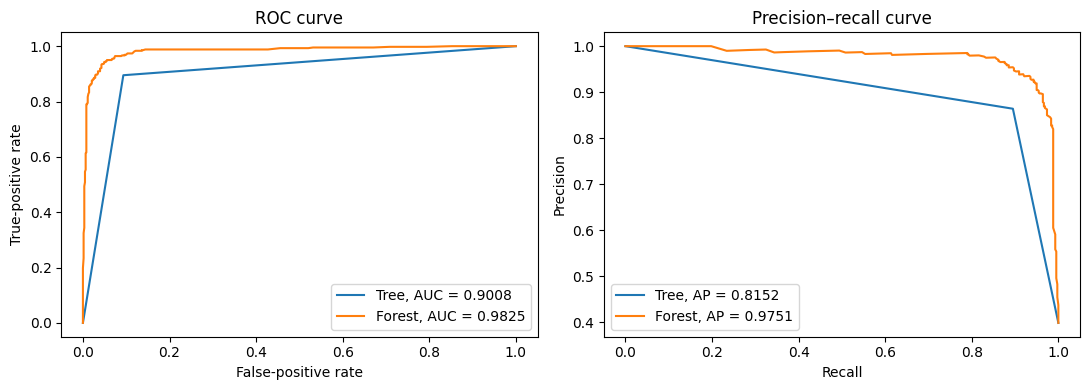

,Predicted legitimate,Predicted spam
Actual legitimate,627,5
Actual spam,95,324


Precision: 98.4802%; recall: 77.3270%; FPR: 0.7911%
The filter flagged 5 of 632 legitimate test mails.


The filter **met** the 1% target on the test split.

In [10]:
fitted_tree = clone(tree).fit(X_train, y_train)
forest_prob = rf.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, prob in [("Tree", fitted_tree.predict_proba(X_test)[:, 1]), ("Forest", forest_prob)]:
    curve_fpr, curve_tpr, _ = roc_curve(y_test, prob)
    curve_precision, curve_recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(curve_fpr, curve_tpr, label=f"{name}, AUC = {roc_auc_score(y_test, prob):.4f}")
    axes[1].plot(curve_recall, curve_precision,
                 label=f"{name}, AP = {average_precision_score(y_test, prob):.4f}")
axes[0].set(title="ROC curve", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].set(title="Precision–recall curve", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

matrix = confusion_matrix(y_test, forest_prob >= threshold, labels=[0, 1])
display(pd.DataFrame(matrix, index=["Actual legitimate", "Actual spam"],
                     columns=["Predicted legitimate", "Predicted spam"]))
tn, fp, fn, tp = matrix.ravel()
test_precision = tp / (tp + fp) if tp + fp else 0
test_recall = tp / (tp + fn)
test_fpr = fp / (tn + fp)
print(f"Precision: {test_precision:.4%}; recall: {test_recall:.4%}; FPR: {test_fpr:.4%}")
print(f"The filter flagged {fp} of {tn + fp} legitimate test mails.")
target_result = "met" if test_fpr <= 0.01 else "missed"
display(Markdown(f"The filter **{target_result}** the 1% target on the test split."))

I use two ways to find important features in the forest. Impurity importance looks at how much each feature helps the trees split training rows. Permutation importance shuffles one test feature at a time and checks how much accuracy changes. I show the top five features for each method. I pick a feature with different ranks and explain why the two methods can give it a different place.

In [11]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10,
                              random_state=SEED, scoring="accuracy")
impurity = pd.Series(rf.feature_importances_, index=feature_names)
permutation = pd.Series(perm.importances_mean, index=feature_names)
display(impurity.nlargest(5).to_frame("Impurity importance"))
display(permutation.nlargest(5).to_frame("Permutation importance"))
imp_rank = impurity.rank(ascending=False, method="min")
perm_rank = permutation.rank(ascending=False, method="min")
top_features = impurity.nlargest(5).index.union(permutation.nlargest(5).index)
feature = (imp_rank - perm_rank).abs().loc[top_features].idxmax()
display(Markdown(f"**{feature}** is number {imp_rank[feature]:.0f} by impurity and "
                 f"number {perm_rank[feature]:.0f} by permutation. Impurity counts "
                 "how much this feature helps the tree splits during training. "
                 "Permutation measures how much test accuracy drops when I shuffle it. "
                 "Other features can give similar information, so these ranks can differ."))

,Impurity importance
char_freq_exclam,0.114799
char_freq_dollar,0.097156
word_freq_remove,0.073441
capital_run_length_average,0.066154
word_freq_free,0.064658


,Permutation importance
word_freq_remove,0.028449
word_freq_hp,0.017983
char_freq_exclam,0.011513
char_freq_dollar,0.006089
word_freq_you,0.004662


**word_freq_hp** is number 9 by impurity and number 2 by permutation. Impurity counts how much this feature helps the tree splits during training. Permutation measures how much test accuracy drops when I shuffle it. Other features can give similar information, so these ranks can differ.

### My answers for Part 2

**Curves.** The forest is much better than the single tree: AUC 0.9825 against 0.9008 and average precision 0.9751 against 0.8152.
The tree curve has only a few points because the leaves of a fully grown tree are pure, so its probabilities are almost only 0 and 1.

**Threshold.** I chose *t* = **0.75** on the out-of-fold probabilities of the training split. At this threshold the out-of-fold FPR is 0.0095 and the recall is 0.8083.

**Did the 1 % target hold on the test split?** **Yes.** On the test split the filter flagged **5 of 632** legitimate mails, so the FPR is 0.0079 (0.79 %), below 1 %.
Precision is 0.9848 and recall is 0.7733. The confusion matrix shows 627 legit mails passed, 5 legit mails flagged, 95 spam mails missed and 324 spam mails caught.
I want to be careful: the out-of-fold FPR (0.95 %) was already close to the limit, and there are only 632 legitimate test mails.
Two more flagged mails would give 7/632 = 1.1 %. So the target held, but with a small margin.
The price of the strict limit is recall: 95 of 419 spam mails (22.7 %) still reach the inbox, and the test recall (0.7733) is lower than the out-of-fold recall (0.8083).

**Importances.** The tables show that the two importances do not give the same order. Example: **`word_freq_hp`** is number 2 in permutation importance (0.01798) but only number 9 in impurity importance.
Another example is `word_freq_you` (number 5 in permutation, number 12 in impurity).
*Why they differ:* impurity importance is calculated while the trees are built, on the training data. It adds the impurity decrease of all splits that use the feature.
Permutation importance is calculated after training, on the test split. I shuffle one column and see how much the accuracy falls.
So permutation importance tells how much the predictions for **new mails** depend on the feature, but impurity importance tells how much the feature helped to fit the **training data**
(and it can be shared between similar features or go to features with many possible split points).
`word_freq_hp` seems to be a feature that the forest really needs on new mails, even if it did not make the biggest impurity decreases in training.
This explanation comes from how the two methods work; I did not test it with extra experiments.

## Part 3 — Voting

I go through the emails one at a time and add the votes for each label. I count the models in their original order. Every model gets one vote unless I pass in a list of weights. I pick the label with the highest total and use the smallest label if there is a tie. I include label zero in the vote table so it can win when all totals are zero.

In [12]:
def hard_vote(predictions, weights=None):
    predictions = np.asarray(predictions)
    n_models, n_samples = predictions.shape
    if weights is None:
        weights = [1] * n_models
    answers = np.zeros(n_samples, dtype=int)
    for i in range(n_samples):
        counts = {0: 0}
        for model_index in range(n_models):
            label = int(predictions[model_index, i])
            counts[label] = counts.get(label, 0) + weights[model_index]
        answers[i] = max(counts, key=lambda label: (counts[label], -label))
    return answers

I fit logistic regression, KNN, and the tree on the same training set. Each model gives one label for every test email. I put the three lists of labels together and pass them to my voting function. I compare my answers with the hard-voting model from scikit-learn. I also show how often each pair of models gives different answers. The disagreement table includes all three pairs: logistic regression and KNN, logistic regression and the tree, and KNN and the tree.

In [13]:
from itertools import combinations
from sklearn.ensemble import VotingClassifier

hard = VotingClassifier(members, voting="hard")
soft = VotingClassifier(members, voting="soft")
fitted_members = [(name, clone(model).fit(X_train, y_train)) for name, model in members]
member_labels = np.stack([model.predict(X_test) for name, model in fitted_members])
manual_labels = hard_vote(member_labels)
library_labels = clone(hard).fit(X_train, y_train).predict(X_test)
print(f"Hard vote agreement: {(manual_labels == library_labels).mean():.6f}")
disagreement = {}
for i, j in combinations(range(len(members)), 2):
    name = f"{members[i][0]} vs {members[j][0]}"
    disagreement[name] = (member_labels[i] != member_labels[j]).mean()
display(pd.Series(disagreement, name="Fraction of different labels").to_frame())

Hard vote agreement: 1.000000


,Fraction of different labels
lr vs knn,0.043768
lr vs tree,0.089439
knn vs tree,0.095147


I compare the three voting members using their scores on the five training folds. The member with the highest mean score is my best single model for this part. I score hard voting and soft voting on the same folds. I subtract the best member's score from each voting score on each fold. I use the mean and spread of those differences to decide whether either voting method clearly does better.

In [14]:
voting_scores = {"lr": scores["lr"], "knn": cv_scores(knn), "tree": scores["tree"],
                 "hard": cv_scores(hard), "soft": cv_scores(soft)}
best_name = max((name for name, model in members), key=lambda name: voting_scores[name].mean())
best_scores = voting_scores[best_name]
print("Best member by CV mean:", best_name)
vote_diffs = {f"{name} - {best_name}": voting_scores[name] - best_scores for name in ("hard", "soft")}
show_scores({**voting_scores, **vote_diffs})
for name, difference in vote_diffs.items():
    display(Markdown(compare(name, difference)))

Best member by CV mean: lr


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
lr,0.931854,0.933439,0.935024,0.934921,0.938095,0.934667,0.002067
knn,0.906498,0.920761,0.917591,0.906349,0.922222,0.914684,0.006909
tree,0.896989,0.885895,0.882726,0.901587,0.914286,0.896297,0.011353
hard,0.923930,0.935024,0.931854,0.941270,0.941270,0.934670,0.006489
soft,0.931854,0.922345,0.919176,0.936508,0.944444,0.930866,0.009235
hard - lr,-0.007924,0.001585,-0.003170,0.006349,0.003175,0.000003,0.005015
soft - lr,0.000000,-0.011094,-0.015848,0.001587,0.006349,-0.003801,0.008304


**hard - lr** has mean +0.0000 and std 0.0050. The difference is inside the spread, so there is no clear winner.

**soft - lr** has mean -0.0038 and std 0.0083. The difference is inside the spread, so there is no clear winner.

### My answers for Part 3

**Reproduce scikit-learn.** My `hard_vote` and `VotingClassifier(voting="hard")` agree on **100 %** of the 1051 test rows (agreement = 1.0000).

**Disagreement.** The members disagree on 4.4 % of test rows (`lr` vs `knn`), 8.9 % (`lr` vs `tree`) and 9.5 % (`knn` vs `tree`).
So `lr` and `knn` are similar, and the tree is the most different member.

**Cross-validation.** The CV means are: `lr` 0.9347, `knn` 0.9147, `tree` 0.8963, hard voting 0.9347, soft voting 0.9309.
The best member is **`lr`**.

- **Hard voting:** `hard − lr` has mean +0.0000 and std 0.0050. The mean is not larger than the std, so the difference is *inside* the fold spread.
  I cannot name a winner: their mean scores are almost the same.
- **Soft voting:** `soft − lr` has mean −0.0038 and std 0.0083. This is also *inside* the fold spread, so I cannot say that soft voting is better or worse than `lr`.

Neither voting method shows a clear gain over the best member. *Possible reason:* voting works well when the members make different mistakes and have similar quality.
Here `lr` is clearly better than `knn` and the tree, and `lr` and `knn` disagree only on 4.4 % of rows. The two weaker members can outvote `lr`, so there is no gain.

## Part 4 — Stacking

I build three columns of spam probabilities, one for each member. For the training table, each probability comes from a model that did not train on that row. I use this table to fit a logistic regression model that combines the three predictions. For the test table, I use the members that were fitted on all the training rows. I check whether my model and scikit-learn have the same weights, test labels, and test accuracy. Keeping the columns in the same order lets me compare the two sets of weights directly.

In [15]:
from sklearn.ensemble import StackingClassifier

meta_train = np.column_stack([
    cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    for name, model in members
])
meta_test = np.column_stack([model.predict_proba(X_test)[:, 1] for name, model in fitted_members])
meta = LogisticRegression().fit(meta_train, y_train)
stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
print("OOF and test matrix shapes:", meta_train.shape, meta_test.shape)
print("Largest coefficient difference:", np.abs(meta.coef_ - stack.final_estimator_.coef_).max())
print("Same test predictions:", np.array_equal(meta.predict(meta_test), stack.predict(X_test)))
print(f"Manual test accuracy: {meta.score(meta_test, y_test):.6f}")
print(f"StackingClassifier test accuracy: {stack.score(X_test, y_test):.6f}")

OOF and test matrix shapes: (3153, 3) (1051, 3)
Largest coefficient difference: 0.0
Same test predictions: True
Manual test accuracy: 0.939106
StackingClassifier test accuracy: 0.939106


I build a second training table from predictions on the same rows the members saw during fitting. I fit another logistic regression model on this table. I compare its weights with the weights from the out-of-fold model and look closely at the tree. A tree can fit training labels closely, so it can get a much larger weight when its predictions are made on rows it already saw. I then score stacking on the five training folds and compare the paired scores with soft voting and the best single model. During cross-validation, stacking makes its own training predictions inside each fold.

In [16]:
naive_train = np.column_stack([model.predict_proba(X_train)[:, 1] for name, model in fitted_members])
naive = LogisticRegression().fit(naive_train, y_train)
coef_table = pd.DataFrame({"Naive": naive.coef_[0], "Out of fold": meta.coef_[0]},
                          index=[name for name, model in members])
display(coef_table.round(6))
display(Markdown(f"The tree weight is {coef_table.loc['tree', 'Naive']:.3f} in the naive fit "
                 f"and {coef_table.loc['tree', 'Out of fold']:.3f} in the OOF fit. "
                 "The tree can fit the labels of rows it sees. The naive final model sees "
                 "these easy predictions, while OOF predictions come from unseen rows."))
stack_scores = cv_scores(stack)
stack_diffs = {f"stack - {best_name}": stack_scores - best_scores,
               "stack - soft": stack_scores - voting_scores["soft"]}
show_scores({"stack": stack_scores, "soft": voting_scores["soft"],
             best_name: best_scores, **stack_diffs})
for name, difference in stack_diffs.items():
    display(Markdown(compare(name, difference)))

,Naive,Out of fold
lr,1.957432,4.013700
knn,1.816307,2.738947
tree,8.280055,1.391370


The tree weight is 8.280 in the naive fit and 1.391 in the OOF fit. The tree can fit the labels of rows it sees. The naive final model sees these easy predictions, while OOF predictions come from unseen rows.

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
stack,0.928685,0.931854,0.935024,0.944444,0.939683,0.935938,0.005595
soft,0.931854,0.922345,0.919176,0.936508,0.944444,0.930866,0.009235
lr,0.931854,0.933439,0.935024,0.934921,0.938095,0.934667,0.002067
stack - lr,-0.003170,-0.001585,0.000000,0.009524,0.001587,0.001271,0.004420
stack - soft,-0.003170,0.009509,0.015848,0.007937,-0.004762,0.005072,0.007857


**stack - lr** has mean +0.0013 and std 0.0044. The difference is inside the spread, so there is no clear winner.

**stack - soft** has mean +0.0051 and std 0.0079. The difference is inside the spread, so there is no clear winner.

### My answers for Part 4

**Comparison with `StackingClassifier`.** My out-of-fold stacking gives the same meta-learner weights as scikit-learn
(`lr` 4.0137, `knn` 2.7389, `tree` 1.3914). The largest absolute difference is 0.0.
The two test predictions are identical, and both test accuracies are 0.9391.

**(a) The weight of the tree.** In the naive fit the tree has weight **8.2801**, in the out-of-fold fit only **1.3914**.
(`lr`: 1.9574 → 4.0137, `knn`: 1.8163 → 2.7389.)
*Why:* the tree is fully grown, so it learns the training rows by heart. If I ask it for probabilities of the same rows it was trained on, it is always right (0 or 1).
The meta-learner sees a "perfect" member and gives it a very big weight. On new data the tree is the weakest member (CV 0.8963), so this trust is wrong.
Out-of-fold probabilities come from trees that did not see the row, so they show the real quality of the tree, and the meta-learner gives the tree a small weight and trusts `lr` more.

**(b) Does stacking win?** The CV means are: stack 0.9359, soft voting 0.9309, `lr` (best member) 0.9347.

- `stack − lr`: mean +0.0013, std 0.0044 → *inside* the fold spread.
- `stack − soft`: mean +0.0051, std 0.0079 → *inside* the fold spread.

So I cannot name a winner. My data cannot separate stacking from the best member or from soft voting.

## Part 5 — AdaBoost and label noise

I use the current row weights to find the share of weight on wrong answers. If that share is zero, I return infinity and divide the weights by their total. Otherwise, I use the weighted error to find alpha. I use alpha to change the weights of the wrong answers. At the end, I divide all the new weights by their total so they add up to one. When the error is above one half, alpha is negative and the wrong answers receive less weight.

In [17]:
import math

def adaboost_step(y_true, y_pred, weights):
    wrong = np.asarray(y_true) != np.asarray(y_pred)
    weights = np.array(weights, dtype=float, copy=True)
    error = weights[wrong].sum() / weights.sum()
    if error == 0:
        return math.inf, weights / weights.sum()
    alpha = math.log((1 - error) / error)
    weights[wrong] *= math.exp(alpha)
    return alpha, weights / weights.sum()

I start the ten rows from the lecture with the same weight. Each stump uses a simple split to predict zero or one. For each round, I print the weighted error, alpha, and all ten new weights. I pass the new weights to the next stump and compare the three rounds with the lecture example.

In [18]:
x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)
w = np.full(10, 0.1)
for round_number, prediction in enumerate([stump_1, stump_2, stump_3], start=1):
    error = w[prediction != y_toy].sum() / w.sum()
    alpha, w = adaboost_step(y_toy, prediction, w)
    print(f"Round {round_number}: error = {error:.4f}, alpha = {alpha:.4f}, weights = {w.round(4)}")
display(Markdown("Round 1 matches the slide check: error 0.300, alpha 0.847, "
                 "and weights about 0.071 for right answers and 0.167 for wrong answers. "
                 "In rounds 2 and 3, the error is about 0.214 and 0.182."))

Round 1: error = 0.3000, alpha = 0.8473, weights = [0.0714 0.0714 0.0714 0.0714 0.0714 0.0714 0.1667 0.1667 0.1667 0.0714]
Round 2: error = 0.2143, alpha = 1.2993, weights = [0.0455 0.0455 0.0455 0.1667 0.1667 0.1667 0.1061 0.1061 0.1061 0.0455]
Round 3: error = 0.1818, alpha = 1.5041, weights = [0.125  0.125  0.125  0.1019 0.1019 0.1019 0.0648 0.0648 0.0648 0.125 ]


Round 1 matches the slide check: error 0.300, alpha 0.847, and weights about 0.071 for right answers and 0.167 for wrong answers. In rounds 2 and 3, the error is about 0.214 and 0.182.

I fit AdaBoost on the training set and start my check with equal weights. For each of the first five stumps, I predict the training labels and calculate the error using the current weights. I use my function to find alpha and the weights for the next stump. I print the biggest gaps between my errors and alphas and the values saved by scikit-learn.

In [19]:
ada.fit(X_train, y_train)
w = np.full(n_train, 1 / n_train)
error_diffs, alpha_diffs = [], []
for i, stump in enumerate(ada.estimators_[:5]):
    prediction = stump.predict(X_train)
    error = w[prediction != y_train].sum() / w.sum()
    alpha, w = adaboost_step(y_train, prediction, w)
    error_diffs.append(abs(error - ada.estimator_errors_[i]))
    alpha_diffs.append(abs(alpha - ada.estimator_weights_[i]))
print("Largest error difference:", max(error_diffs))
print("Largest alpha difference:", max(alpha_diffs))

Largest error difference: 1.1102230246251565e-16
Largest alpha difference: 4.440892098500626e-16


I fit AdaBoost once per training fold and score each round on that fold's validation rows. I average the five curves and choose the earliest round with the highest mean validation accuracy. Then I draw the training and test error curves and mark the round chosen by CV. I find the smallest test error on the plot and compare it with the error at my chosen round. I check whether this gap is larger than one test standard error. I use the test curve to describe the result after choosing the round on the training folds.

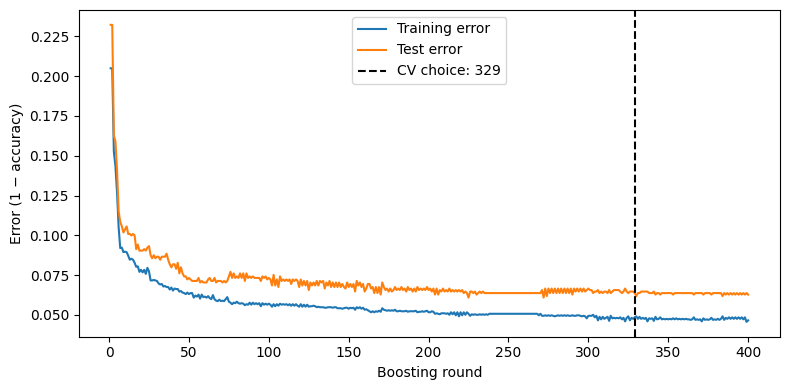

CV picks round **329**, with test error 6.3749%. The lowest test error is 6.0894% at round **225**. The gap is 0.2854%, which is at most one standard error (0.7536%).

In [20]:
validation_curves = []
for fit_rows, val_rows in cv.split(X_train, y_train):
    model = clone(ada).fit(X_train[fit_rows], y_train[fit_rows])
    validation_curves.append(list(model.staged_score(X_train[val_rows], y_train[val_rows])))
chosen_round = int(np.argmax(np.mean(validation_curves, axis=0))) + 1

train_error = 1 - np.array(list(ada.staged_score(X_train, y_train)))
test_error = 1 - np.array(list(ada.staged_score(X_test, y_test)))
rounds = np.arange(1, len(train_error) + 1)
plt.figure(figsize=(8, 4))
plt.plot(rounds, train_error, label="Training error")
plt.plot(rounds, test_error, label="Test error")
plt.axvline(chosen_round, color="black", linestyle="--", label=f"CV choice: {chosen_round}")
plt.xlabel("Boosting round")
plt.ylabel("Error (1 − accuracy)")
plt.legend()
plt.tight_layout()
plt.show()

test_best = int(test_error.argmin()) + 1
chosen_error = test_error[chosen_round - 1]
minimum_error = test_error[test_best - 1]
p = 1 - chosen_error
chosen_se = np.sqrt(p * (1 - p) / len(y_test))
relation = "more than" if chosen_error - minimum_error > chosen_se else "at most"
display(Markdown(f"CV picks round **{chosen_round}**, with test error {chosen_error:.4%}. "
                 f"The lowest test error is {minimum_error:.4%} at round **{test_best}**. "
                 f"The gap is {chosen_error - minimum_error:.4%}, which is {relation} "
                 f"one standard error ({chosen_se:.4%})."))

I make a copy of the training labels so the original labels stay clean. I set the seed and pick the rows to change without picking any row twice. For each chosen row, I change zero to one or one to zero. I return both the changed labels and the row numbers so I can check the weights of those rows later. In the next cell I repeat this with five seeds and keep the test labels clean.

In [21]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx

I first fit the tree, the forest, and AdaBoost with 200 rounds on the clean training labels. I use their test scores as my starting point. In each draw, I flip the same training labels for all three models and score them on the clean test set. I subtract each noisy score from its clean score to find the loss in accuracy. For AdaBoost, I also replay the weight updates for its fitted stumps. I add up the weights of the flipped rows and compare that share with their starting share. The five losses in the table show how much the result changes when I flip a different set of rows.

In [22]:
ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}
clean = {name: clone(model).fit(X_train, y_train).score(X_test, y_test)
         for name, model in noise_models.items()}
noisy = {name: [] for name in noise_models}
weight_shares = []
for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)
    for name, model in noise_models.items():
        fitted = clone(model).fit(X_train, y_noisy)
        noisy[name].append(fitted.score(X_test, y_test))
        if name == "ada200":
            w = np.full(n_train, 1 / n_train)
            for stump in fitted.estimators_:
                _, w = adaboost_step(y_noisy, stump.predict(X_train), w)
            weight_shares.append((len(idx) / n_train, w[idx].sum()))

losses = {name: clean[name] - np.array(noisy[name]) for name in noise_models}
summary = []
for name in noise_models:
    summary.append([clean[name], np.mean(noisy[name]), np.std(noisy[name]),
                    losses[name].mean(), losses[name].std()])
display(pd.DataFrame(summary, index=list(noise_models), columns=[
    "Clean accuracy", "Noisy mean", "Noisy std", "Loss mean", "Loss std"]).round(6))
show_scores(losses, prefix="Draw")

shares = np.array(weight_shares)
display(pd.DataFrame(shares, index=range(1, 6), columns=["Before", "After"]).round(6))
print(f"Before mean ± std: {shares[:, 0].mean():.4%} ± {shares[:, 0].std():.4%}")
print(f"After mean ± std: {shares[:, 1].mean():.4%} ± {shares[:, 1].std():.4%}")

,Clean accuracy,Noisy mean,Noisy std,Loss mean,Loss std
tree,0.901998,0.719315,0.014826,0.182683,0.014826
rf,0.941009,0.897050,0.005225,0.043958,0.005225
ada200,0.934348,0.906565,0.002911,0.027783,0.002911


,Draw 1,Draw 2,Draw 3,Draw 4,Draw 5,Mean,Std
tree,0.196004,0.183635,0.188392,0.191246,0.154139,0.182683,0.014826
rf,0.053283,0.037108,0.043768,0.042816,0.042816,0.043958,0.005225
ada200,0.028544,0.031399,0.022835,0.026641,0.029496,0.027783,0.002911


,Before,After
1,0.200127,0.390958
2,0.200127,0.387008
3,0.200127,0.402408
4,0.200127,0.403816
5,0.200127,0.400596


Before mean ± std: 20.0127% ± 0.0000%
After mean ± std: 39.6957% ± 0.6708%


I sort the models by their average loss in test accuracy. For every pair, I compare their losses from the same draw. I use the spread of those paired differences to check whether the order is clear. I also look at how much weight AdaBoost gives the flipped rows before and after fitting. I use these results to explain how the models react to wrong training labels.

In [23]:
noise_order = sorted(losses, key=lambda name: losses[name].mean(), reverse=True)
print("Largest mean loss:", noise_order[0])
for first, second in combinations(noise_order, 2):
    display(Markdown(compare(f"{first} loss - {second} loss", losses[first] - losses[second])))
display(Markdown(f"Flipped rows carry {shares[:, 0].mean():.1%} of the weight at first "
                 f"and {shares[:, 1].mean():.1%} after AdaBoost. "
                 "AdaBoost gives more weight to hard rows when its stumps get them wrong. "
                 "A deep tree can also fit wrong labels in small leaves, while a forest "
                 "averages the predictions of many trees trained on different samples."))

Largest mean loss: tree


**tree loss - rf loss** has mean +0.1387 and std 0.0138. The first value is higher by more than the spread.

**tree loss - ada200 loss** has mean +0.1549 and std 0.0161. The first value is higher by more than the spread.

**rf loss - ada200 loss** has mean +0.0162 and std 0.0065. The first value is higher by more than the spread.

Flipped rows carry 20.0% of the weight at first and 39.7% after AdaBoost. AdaBoost gives more weight to hard rows when its stumps get them wrong. A deep tree can also fit wrong labels in small leaves, while a forest averages the predictions of many trees trained on different samples.

## My answers for Part 5

**The lecture's three rounds.** Round 1 gives ε = 0.3, α = 0.847, weights 0.071 on the right rows and 0.167 on the wrong rows.
This is the same as the numbers in the task text. Round 2 gives ε = 0.2143, α = 1.2993. Round 3 gives ε = 0.1818, α = 1.5041.
In every round the new weights sum to 1.

**Check scikit-learn.** For the first five stumps the largest absolute difference is 1.1e-16 for ε and 4.4e-16 for α.
So `adaboost_step` makes the same update as scikit-learn (the difference is only floating-point rounding).

**Error by round.** The training error falls from 0.2049 (round 1) to 0.0466 (round 400). The test error falls from 0.2322 to 0.0628: it is 0.1037 at round 10, 0.0733 at rounds 50 and 100, 0.0657 at round 200 and 0.0628 at round 400. So after round 50 it improves only slowly.

**(a) Chosen round and the best test round.** On the training folds the highest mean accuracy is at round **329** (0.9410). The lowest test error is at round **225** (0.0609).
At my chosen round the test error is 0.0637. The difference between the two test errors is 0.0029 and the standard error is 0.0075.
The difference is **not larger** than the standard error, so the two rounds are not really different on this test split.
Also, the round 225 is found by looking at the test curve, so its error is a little optimistic. My round 329 was chosen without the test split, so 0.0637 is the honest number.

**(b) Which model loses the most with 20 % noise?** The **single tree** loses the most.

| model | acc 0 % | acc 20 % (mean ± std) | loss (mean ± std) |
|---|---|---|---|
| tree | 0.9020 | 0.7193 ± 0.0148 | 0.1827 ± 0.0148 |
| rf | 0.9410 | 0.8971 ± 0.0052 | 0.0440 ± 0.0052 |
| ada200 | 0.9343 | 0.9066 ± 0.0029 | 0.0278 ± 0.0029 |

The order of losses is tree > rf > ada200. I paired the losses by draw: `tree − rf` = +0.1387 (std 0.0138), `ada200 − rf` = −0.0162 (std 0.0065) and `ada200 − tree` = −0.1549 (std 0.0161).
In all three cases the absolute mean difference is bigger than the std (and the sign is the same in all five draws), so the order is **larger than the spread** over the draws.
At 20 % noise `ada200` (0.9066) is even a little better than `rf` (0.8971), but at 0 % noise `rf` was better (0.9410 against 0.9343).

The flipped rows started with about 20.0% of the total weight. After AdaBoost they held about 39.7% on average. A single deep tree can make splits that follow wrong labels, which helps explain why its test accuracy fell the most. The forest averages many trees, which can reduce the effect of individual bad splits.

## Part 6 — Recommendation and reproducibility

I use the forest threshold chosen from the training folds to make my recommendation. I report how many normal test emails were flagged and how much spam the filter caught. I also report precision and the forest's CV accuracy. Then I compare the forest with the other models fold by fold. I say which differences are inside the fold spread because those scores cannot show a clear winner.

In [24]:
all_candidates = {**scores, **voting_scores, "stack": stack_scores}
inside = []
for name, values in all_candidates.items():
    difference = scores["rf"] - values
    if name != "rf" and abs(difference.mean()) <= difference.std():
        inside.append(name)
spread_sentence = (
    f"The forest's CV differences against {', '.join(inside)} are inside the fold spread."
    if inside else "None of the forest's CV differences against the other candidates is inside the fold spread."
)
verdict = ("I recommend the forest at this threshold for this dataset."
           if test_fpr <= 0.01 else
           "I would keep the forest as a candidate, but I would not deploy it under the 1% rule yet.")
display(Markdown(
    f"{verdict} The threshold is **{threshold}**, with OOF FPR {fpr[best_index]:.2%} "
    f"and OOF recall {best_recall:.2%}. On the test set it flags {fp} of {tn + fp} real mails "
    f"(FPR {test_fpr:.2%}) and catches {test_recall:.2%} of spam. "
    f"Test precision is {test_precision:.2%}, and the forest CV accuracy is {rf_mean:.2%}. "
    f"{spread_sentence}"
))

I recommend the forest at this threshold for this dataset. The threshold is **0.75**, with OOF FPR 0.95% and OOF recall 80.83%. On the test set it flags 5 of 632 real mails (FPR 0.79%) and catches 77.33% of spam. Test precision is 98.48%, and the forest CV accuracy is 94.83%. None of the forest's CV differences against the other candidates is inside the fold spread.

### Recommendation

I recommend the **random forest** with a threshold of **0.75**, chosen using out-of-fold probabilities from the training set. It flagged **5 of 632** normal test emails, so its false-positive rate of **0.79%** met the 1% target. Its precision was **98.48%** and its recall was **77.33%**. It had a mean CV accuracy of **94.83%**, and its paired differences against logistic regression, hard voting, soft voting, and stacking were outside the fold spread. Bagged logistic regression versus logistic regression, both voting methods versus logistic regression, and stacking versus logistic regression and soft voting were inside the fold spread. The error gap between AdaBoost rounds 329 and 225 was also within one test standard error.

### Reproducibility

The first code cell prints the library versions. My seed is **2345**. I use the original CSV and the package versions from the starter requirements. The local project has at least three commits.